# Composite figure: BT (top-left), hexagon map (top-right), rotated heatmap (bottom)

Generates `ICRA_paper_overleaf/fig_composite_v2.png`.
Layout: 2\u00d72 grid \u2014 top row = behavior tree (left) + hexagon map (right);
bottom row = full-width rotated heatmap of Nav2 system tests vs 25 behaviors.

In [1]:
import csv, subprocess
from pathlib import Path
from collections import defaultdict
from xml.etree import ElementTree

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np, pandas as pd, seaborn as sns, networkx as nx
from PIL import Image

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
SYSTEM_ROOT = DATA_ROOT / "nav2_system_tests"
np.random.seed(0)

/home/sam/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
/home/sam/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
def parse_bt_xml(xml_path):
    root = ElementTree.parse(xml_path).getroot()
    trees = {bt.get("ID"): bt for bt in root.iter("BehaviorTree")}
    main = trees[root.get("main_tree_to_execute")] or next(iter(trees.values()))
    names, parents, classes = [], {}, {}
    def walk(el, pid, active):
        nid = len(names)
        names.append(el.get("name") or el.tag); parents[nid] = pid; classes[nid] = el.tag
        me = nid
        for ch in list(el):
            if ch.tag == "SubTree":
                sub = trees.get(ch.get("ID"))
                if sub is not None and ch.get("ID") not in active:
                    for sc in list(sub): walk(sc, me, active | {ch.get("ID")})
            else: walk(ch, me, active)
    for ch in list(main): walk(ch, None, {root.get("main_tree_to_execute")})
    return dict(names=names, parents=parents, classes=classes)

def baseline_reached_set():
    out = set()
    for p in SYSTEM_ROOT.rglob("nav2_behaviors.csv"):
        if not p.parent.name.isdigit(): continue
        with open(p) as f: rows = list(csv.DictReader(f))
        nm = {r["behavior_name"] for r in rows}
        if "ComputePathToPose" in nm and "NavigateThroughPoses" not in nm:
            last = {r["behavior_name"]: r["status_name"] for r in rows if r["behavior_name"]}
            out |= {b for b, s in last.items() if s not in ("IDLE", "INVALID", "")}
    return out

In [3]:
EDGE_TYPES = {"Control":"#0072b2","Recovery":"#cc79a7","RecoveryAction":"#d55e00",
                 "ClearCostmap":"#56b4e9","Condition":"#e69f00"}

def node_type(tag, name):
    if tag in ("Sequence","Fallback","ReactiveFallback","PipelineSequence","RoundRobin",
               "ControllerSelector","PlannerSelector","RateController"): return "Control"
    if tag == "RecoveryNode": return "Recovery"
    if tag == "ClearEntireCostmap": return "ClearCostmap"
    return "RecoveryAction" if name in ("Spin","Wait","BackUp") else "Condition"

def tree_pos(names, parents):
    children, roots = defaultdict(list), []
    for i, p in parents.items(): (roots if p is None else children[p]).append(i)
    depth = {}
    def dfs(i, d):
        depth[i] = d
        for j in children[i]: dfs(j, d+1)
    for r in roots: dfs(r, 0)
    layers = defaultdict(list)
    for i in range(len(names)): layers[depth[i]].append(i)
    return {i: (k-(m-1)/2, -d*1.6) for d, ms in layers.items() for k, i in enumerate(ms) for m in [len(ms)]}

In [4]:
# data: tree, reached set, hexagon map
TO_POSE_XML = SYSTEM_ROOT/"system"/"test-bt-navigator-2026-09-06-10075304"\
              /"_config"/"files"/"navigate_to_pose_w_replanning_and_recovery.xml"
t = parse_bt_xml(TO_POSE_XML)
declared = set(t["names"])
reached  = baseline_reached_set() & declared
print(f"nav_to_pose: {sum(1 for d in declared if d in reached)}/{len(declared)} nodes executed")

HEX = np.asarray(Image.open(SYSTEM_ROOT/"system"/"test-bt-navigator-2026-09-06-10075304"\
        /"_config"/"environments"/"hexagon"/"maps"/"hexagon.pgm"), dtype=np.float32)

nav_to_pose: 7/22 nodes executed


/tmp/ipykernel_1621676/3612398177.py:4: DeprecationWarning: Testing an element's truth value will raise an exception in future versions.  Use specific 'len(elem)' or 'elem is not None' test instead.
  main = trees[root.get("main_tree_to_execute")] or next(iter(trees.values()))


In [5]:
def nav2_matrix():
    to_pose = SYSTEM_ROOT/"system"/"test-bt-navigator-2026-09-06-10075304"\
              /"_config"/"files"/"navigate_to_pose_w_replanning_and_recovery.xml"
    thru = SYSTEM_ROOT/"system"/"test-nav-through-poses-2026-09-06-10461058"\
           /"_config"/"files"/"navigate_through_poses_w_replanning_and_recovery.xml"
    universe = set(parse_bt_xml(to_pose)["names"]) | set(parse_bt_xml(thru)["names"])
    direct = {"test-spin-behavior-2026-09-06-15094116":{"Spin"},
              "test-wait-behavior-2026-09-06-15015548":{"Wait"},
              "test-error-codes-2026-09-06-14382214":{"FollowPath","ComputePathToPose","ComputePathThroughPoses"}}
    excluded = {"test-drive-on-heading-behavior-2026-09-06-15242717",
                "test-bt-navigator-with-wrong-init-pose-2026-09-06-10143726"}
    counts = {}
    for c in sorted(p.parent for p in SYSTEM_ROOT.rglob("campaign.db") if p.parent.name not in excluded):
        cnt = {b: 0 for b in universe}
        if c.name in direct:
            n = sum(1 for p in c.rglob("behaviors.jsonl") if p.parent.name.isdigit())
            for b in direct[c.name]: cnt[b] = n
        else:
            for csvp in c.rglob("nav2_behaviors.csv"):
                if not csvp.parent.name.isdigit(): continue
                with open(csvp) as f:
                    hit = {r["behavior_name"] for r in csv.DictReader(f)
                           if r.get("status_name","") not in ("INVALID","IDLE","")}
                for b in hit & universe: cnt[b] += 1
        counts[c.name] = cnt
    return universe, counts

order = ["spin","wait","bt-node","costmap","error-codes","localization","planning",
         "bt-dijkstra","bt-navigator","dyn-obst","nav-through","fails-nav",
         "waypoints","wypt-outside","wypt-stop"]
abbr = {"spin":"test-spin-behavior-2026-09-06-15094116","wait":"test-wait-behavior-2026-09-06-15015548",
        "bt-node":"test-behavior-tree-node-2026-09-06-16170101","costmap":"costmap-filter-2026-09-06-13464724",
        "error-codes":"test-error-codes-2026-09-06-14382214","localization":"test-localization-2026-09-06-16464638",
        "planning":"planning-2026-09-06-18165849","bt-dijkstra":"test-bt-navigator-with-dijkstra-2026-09-06-10102725",
        "bt-navigator":"test-bt-navigator-2026-09-06-10075304","dyn-obst":"test-dynamic-obstacle-2026-09-06-10363206",
        "nav-through":"test-nav-through-poses-2026-09-06-10461058","fails-nav":"test-failure-navigator-2026-09-06-14285835",
        "waypoints":"test-waypoint-follower-2026-09-06-14105254","wypt-outside":"test-waypoint-follower-outside-map-2026-09-06-14134612",
        "wypt-stop":"test-waypoint-follower-stop-on-failure-2026-09-06-14223244"}

universe, counts = nav2_matrix()
ntests = {b: sum(1 for c in order if counts[abbr[c]][b] > 0) for b in universe}
behaviors = sorted(universe, key=lambda b: (ntests[b], b))
M = pd.DataFrame({c: [counts[abbr[c]][b] for b in behaviors] for c in order}, index=behaviors)

/tmp/ipykernel_1621676/3612398177.py:4: DeprecationWarning: Testing an element's truth value will raise an exception in future versions.  Use specific 'len(elem)' or 'elem is not None' test instead.
  main = trees[root.get("main_tree_to_execute")] or next(iter(trees.values()))


saved: /home/sam/Downloads/ICRA analysis/ICRA_paper_overleaf/fig_composite_v2.png


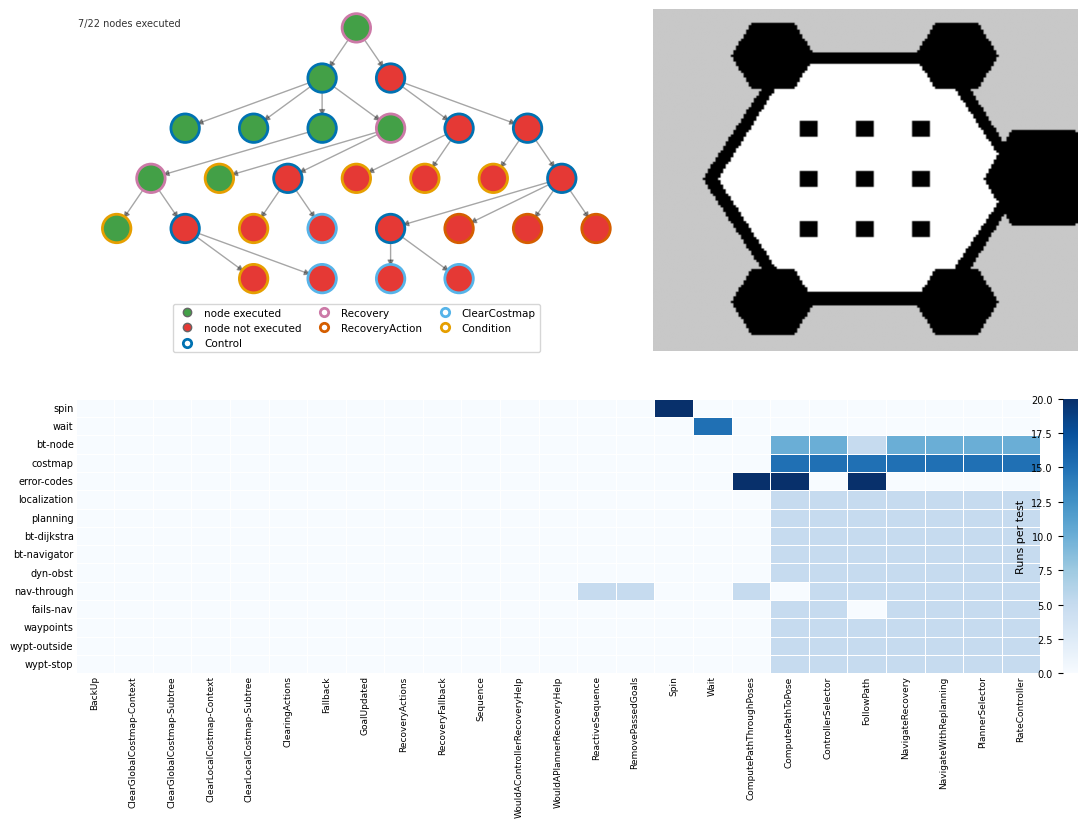

In [8]:
# ---- combined figure ----
fig = plt.figure(figsize=(10.5, 8.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1.35, 1.65, 0.05],
                      height_ratios=[1.25, 1.0], wspace=0.07, hspace=0.15,
                      left=0.035, right=0.99, top=0.94, bottom=0.13)
axh  = fig.add_subplot(gs[1, 0:2])    # heatmap matrix (spans cols 0-1)
axcb = fig.add_subplot(gs[1, 2])      # dedicated colorbar

# explicit axes for top band (BT, legend slot, map)
row0 = fig.add_subplot(gs[0, :]); row0.remove()          # read full row position
r0 = row0.get_position()                                  # (x0, y0, w, h)
legend_h = 0.16                                           # fraction of row0 for legend
tree_h   = 1.0 - legend_h
axt   = fig.add_axes([r0.x0, r0.y0 + r0.height*legend_h, r0.width*0.56, r0.height*tree_h])
axleg = fig.add_axes([r0.x0, r0.y0, r0.width*0.56, r0.height*legend_h]); axleg.axis("off")
map_l = r0.x0 + r0.width*0.56 + 0.015
axm   = fig.add_axes([map_l, r0.y0, r0.x0+r0.width-map_l, r0.height])

# top-left: behavior tree (green executed / red unexecuted) + legend
pos = tree_pos(t["names"], t["parents"])
G = nx.DiGraph(); G.add_edges_from((p,i) for i,p in t["parents"].items() if p is not None)
node_c = ["#43a047" if n in reached else "#e53935" for n in t["names"]]
edge_c = [EDGE_TYPES[node_type(t["classes"][i], t["names"][i])] for i in range(len(t["names"]))]
nx.draw_networkx_edges(G, pos, ax=axt, alpha=0.35, arrows=True, arrowsize=9)
nx.draw_networkx_nodes(G, pos, ax=axt, node_color=node_c, node_size=420,
                       edgecolors=edge_c, linewidths=2.0)
xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
axt.set_xlim(min(xs)-0.6, max(xs)+0.6)
axt.set_ylim(min(ys)-0.6, max(ys)+0.6)
axt.text(0.005, 0.97, f"{sum(1 for d in declared if d in reached)}/{len(declared)} nodes executed",
         transform=axt.transAxes, fontsize=7, va="top", color="0.2")
axt.set_axis_off()
reach_h = [Line2D([0],[0], marker="o", ls="", mfc="#43a047", mec="0.4", ms=6, label="node executed"),
           Line2D([0],[0], marker="o", ls="", mfc="#e53935", mec="0.4", ms=6, label="node not executed")]
type_h = [Line2D([0],[0], marker="o", ls="", mfc="w", mec=c, mew=2, ms=6, label=k) for k,c in EDGE_TYPES.items()]
axt.legend(handles=reach_h+type_h, loc="lower center", bbox_to_anchor=(0.5, 0.0),
           bbox_transform=axleg.transAxes,
           ncol=3, fontsize=7.5, frameon=True, borderaxespad=0.0, columnspacing=1.2, handletextpad=0.6)

# top-right: hexagon map (same height as BT + legend)
axm.imshow(HEX, cmap="gray", origin="upper", aspect="auto")
axm.set_xlim(0, HEX.shape[1]); axm.set_ylim(HEX.shape[0], 0)
axm.set_axis_off()

# bottom: rotated heatmap (tests on y, behaviors on x) + dedicated colorbar
sns.heatmap(M.T, ax=axh, cmap="Blues", cbar_ax=axcb, cbar=True,
            linewidths=0.4, linecolor="white", xticklabels=True, yticklabels=True)
axcb.yaxis.set_ticks_position("left")
axcb.yaxis.set_label_position("left")
axcb.set_ylabel("Runs per test", fontsize=8)
axcb.tick_params(axis="y", labelsize=7)
axh.tick_params(length=0, pad=1.5)
axh.set_xticklabels(axh.get_xticklabels(), rotation=90, fontsize=6.5, ha="center")
axh.set_yticklabels(axh.get_yticklabels(), fontsize=7)

out = DATA_ROOT/"ICRA_paper_overleaf"/"fig_composite_v2.png"
fig.savefig(out, dpi=300)
print(f"saved: {out}")